In [7]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("GPU:", tf.config.list_physical_devices("GPU"))   # should NOT be empty

project = "/content/drive/MyDrive/DS340project/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
X_spec   = np.load(project + "X.npy").astype("float32")        # (767, 128, 1292)
y_spec   = np.load(project + "y.npy").astype(int)              # mood 0-3
spec_ids = np.load(project + "spec_music_ids.npy").astype(int) # from Abigail

train_ids = np.load(project + "train_music_ids.npy").astype(int)
test_ids  = np.load(project + "test_music_ids.npy").astype(int)

#check that audio labels match with lyrics labels
lyr_ids = np.load(project + "music_ids_filtered.npy").astype(int)
lyr_y = np.load(project + "y_lyrics_filtered.npy").astype(int)

audio_labels = pd.Series(y_spec, index=spec_ids).loc[lyr_ids].values
print("Labels match:", np.array_equal(audio_labels, lyr_y))

#keep songs in the train or test set
keep = np.isin(spec_ids, np.concatenate((train_ids, test_ids)))
X_spec = X_spec[keep]
y_spec = y_spec[keep]
spec_ids = spec_ids[keep]

#split each mood label into valence and arousal
Y = np.column_stack((y_spec % 2, y_spec // 2)).astype("float32")

is_train = np.isin(spec_ids, train_ids)
is_test = np.isin(spec_ids, test_ids)

print("Training songs:", is_train.sum())
print("Testing songs:", is_test.sum())

Labels match: True
Training songs: 484
Testing songs: 121


In [9]:
min_value = X_spec[is_train].min()
max_value = X_spec[is_train].max()
X_img = (X_spec - min_value) / (max_value - min_value)                               # scale to 0-1

X_img = tf.image.resize(X_img[..., np.newaxis], (224, 224)).numpy()  # MobileNet size

X_img = X_img * 2 - 1                                             # MobileNet expects -1 to 1
del X_spec                                                        # free memory




X_train, X_test = X_img[is_train], X_img[is_test]
Y_train, Y_test = Y[is_train], Y[is_test]
print(X_train.shape, X_test.shape)    # (484, 224, 224, 1) (121, 224, 224, 1)

(484, 224, 224, 1) (121, 224, 224, 1)


In [10]:
def weighted_loss(Y_train_part):
    # Find the proportion of positive examples for each output
    positive_rate = Y_train_part.mean(axis=0)
    positive_weight = 0.5 / positive_rate
    negative_weight = 0.5 / (1 - positive_rate)

    def loss(y_true, y_pred):
        # Avoid taking the log of zero
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)

        positive_loss = positive_weight * y_true * tf.math.log(y_pred)
        negative_loss = negative_weight * (1 - y_true) * tf.math.log(1 - y_pred)
        return tf.reduce_mean(-(positive_loss + negative_loss))

    return loss


def build_model():
    # Load MobileNetV2 without its original classification layer
    base_model = MobileNetV2(
        input_shape=(224, 224, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False

    # The spectrogram is grayscale, so repeat it across three channels
    inputs = layers.Input(shape=(224, 224, 1))
    x = layers.Concatenate()([inputs, inputs, inputs])
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(2, activation="sigmoid")(x)

    model = models.Model(inputs=inputs, outputs=outputs)
    return model, base_model


def train_cnn(X_part, Y_part, verbose=0):
    # Set aside 15% of this training data for validation
    indices = np.random.RandomState(SEED).permutation(len(X_part))
    validation_size = int(0.15 * len(X_part))
    val_indices = indices[:validation_size]
    train_indices = indices[validation_size:]

    X_fit = X_part[train_indices]
    Y_fit = Y_part[train_indices]
    X_val = X_part[val_indices]
    Y_val = Y_part[val_indices]

    model, base_model = build_model()
    loss_function = weighted_loss(Y_fit)

    early_stop = tf.keras.callbacks.EarlyStopping(
        patience=5,
        restore_best_weights=True
    )

    # First train the new layers while MobileNetV2 is frozen
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=loss_function
    )
    model.fit(
        X_fit, Y_fit,
        validation_data=(X_val, Y_val),
        epochs=30,
        batch_size=32,
        callbacks=[early_stop],
        verbose=verbose
    )

    # Fine-tune the last 30 layers using a smaller learning rate
    base_model.trainable = True
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
        loss=loss_function
    )
    model.fit(
        X_fit, Y_fit,
        validation_data=(X_val, Y_val),
        epochs=20,
        batch_size=32,
        callbacks=[early_stop],
        verbose=verbose
    )

    return model

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 17s 748ms/step - loss: 0.7182 - val_loss: 0.6431
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.6355 - val_loss: 0.5779
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.5821 - val_loss: 0.5452
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.5488 - val_loss: 0.5249
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.4992 - val_loss: 0.5172
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.4845 - val_loss: 0.5097
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.4856 - val_loss: 0.5056
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.4572 - val_loss: 0.5071
Epoch 9/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.4551 - val_loss: 0.5022
Epoch 10/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.4575 - val_loss: 0.5049
Epoch 11/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.4395 - val_loss: 0.5044
Epoch 12/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0

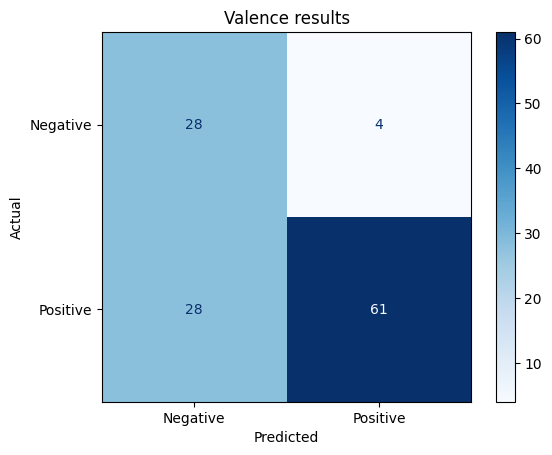

Arousal accuracy: 0.777 macro-F1: 0.731


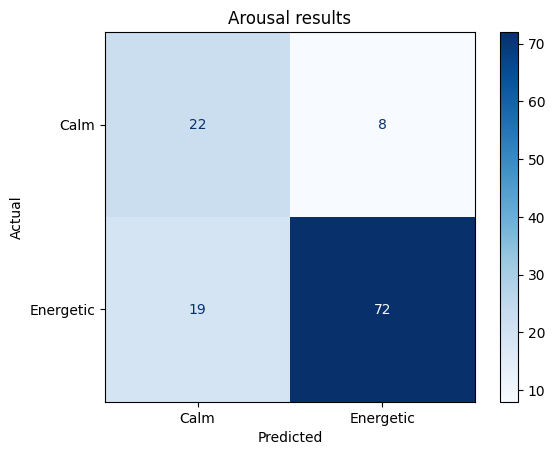

Combined mood accuracy: 0.628
Combined mood macro-F1: 0.388


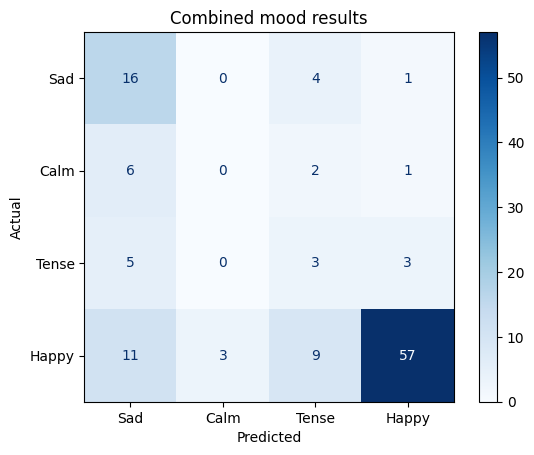

In [11]:
model = train_cnn(X_train, Y_train, verbose=1)

# Get the predicted probabilities and turn them into 0/1 predictions
P_test = model.predict(X_test)
pred = (P_test >= 0.5).astype(int)

# Save the probabilities for the test songs
test_results = pd.DataFrame({
    "musicId": spec_ids[is_test],
    "cnn_valence_prob": P_test[:, 0],
    "cnn_arousal_prob": P_test[:, 1]
})
test_results.to_csv(project + "cnn_probs_test.csv", index=False)

# Evaluate valence and arousal separately
for column, name, labels in [
    (0, "Valence", ["Negative", "Positive"]),
    (1, "Arousal", ["Calm", "Energetic"])
]:
    accuracy = accuracy_score(Y_test[:, column], pred[:, column])
    f1 = f1_score(Y_test[:, column], pred[:, column], average="macro")
    print(name, "accuracy:", round(accuracy, 3), "macro-F1:", round(f1, 3))

    ConfusionMatrixDisplay.from_predictions(
        Y_test[:, column],
        pred[:, column],
        display_labels=labels,
        cmap="Blues"
    )
    plt.title(name + " results")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# Also check the combined mood category
true_mood = 2 * Y_test[:, 1] + Y_test[:, 0]
pred_mood = 2 * pred[:, 1] + pred[:, 0]

accuracy = accuracy_score(true_mood, pred_mood)
f1 = f1_score(true_mood, pred_mood, average="macro")
print("Combined mood accuracy:", round(accuracy, 3))
print("Combined mood macro-F1:", round(f1, 3))

ConfusionMatrixDisplay.from_predictions(
    true_mood,
    pred_mood,
    display_labels=["Sad", "Calm", "Tense", "Happy"],
    cmap="Blues"
)
plt.title("Combined mood results")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = np.zeros_like(Y_train)

# Make one mood label so the folds keep a similar mix of the four mood groups
mood_train = 2 * Y_train[:, 1] + Y_train[:, 0]

for fold, (train_index, val_index) in enumerate(skf.split(X_train, mood_train)):
    tf.keras.backend.clear_session()

    fold_model = train_cnn(X_train[train_index], Y_train[train_index])
    fold_predictions = fold_model.predict(X_train[val_index], verbose=0)
    oof[val_index] = fold_predictions

    print("Finished fold", fold + 1, "out of 5")

# Save the out-of-fold predictions
train_results = pd.DataFrame({
    "musicId": spec_ids[is_train],
    "cnn_valence_prob": oof[:, 0],
    "cnn_arousal_prob": oof[:, 1]
})
train_results.to_csv(project + "cnn_oof_train.csv", index=False)

Finished fold 1 out of 5
Finished fold 2 out of 5
Finished fold 3 out of 5
Finished fold 4 out of 5
Finished fold 5 out of 5
